krzywe uczenia
Najlepsza epoka: 33


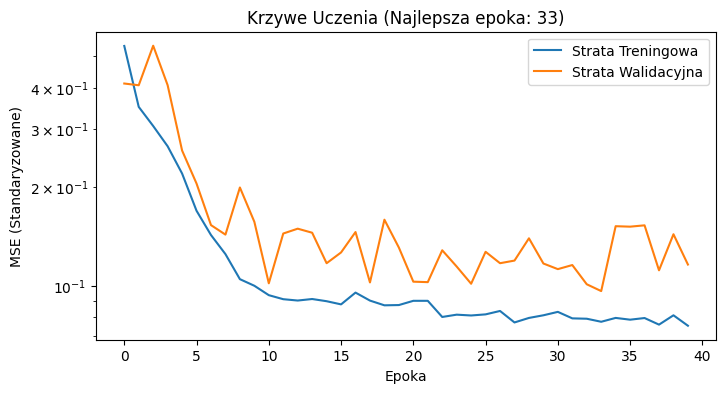

Ocena jedno i wielokrokowa
            Metoda      MAE     RMSE
GRU (Jednokrokowo) 2.503663 3.210880
        GRU (H=14) 3.063834 3.825066
   Sezonowy (H=14) 3.641186 4.443427
     Naiwny (H=14) 8.814871 9.430081


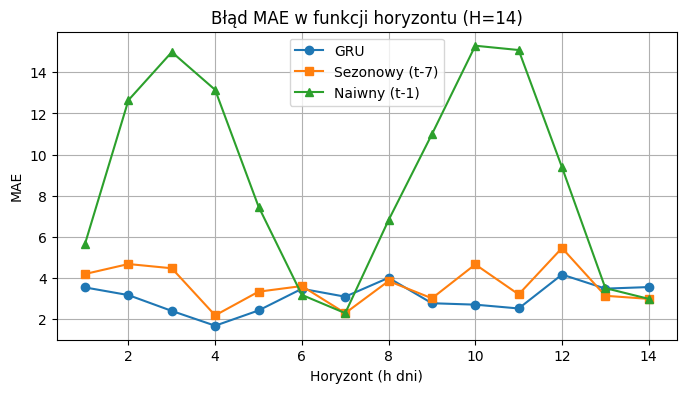

wpływ długości okna
 Okno  Ziarno  Strata Walidacyjna (MSE)  MAE (1-krok)  MAE (Wielokrokowe)
    3       0                    0.3027          4.66                8.59
    3       1                    0.3060          4.43                7.82
    7       0                    0.1097          2.90                4.57
    7       1                    0.0950          2.84                4.70
   28       0                    0.0962          2.50                3.06
   28       1                    0.0798          2.47                3.12

Najlepsze okno: 28
Średni błąd walidacyjny dla okna 28 wyniósł: 0.0880


In [6]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

def generuj_sprzedaz(n=1000):
    t = np.arange(n)
    trend = 0.02 * t
    tygodniowa = 8 * np.sin(2 * np.pi * t / 7)
    roczna = 15 * np.sin(2 * np.pi * t / 365)
    szum = np.random.randn(n) * 3
    return (100 + trend + tygodniowa + roczna + szum).astype(np.float32)

seria = generuj_sprzedaz(1000)
n = len(seria)
i_tr, i_va = int(0.7 * n), int(0.85 * n)

#standaryzacja
mu, sd = seria[:i_tr].mean(), seria[:i_tr].std()
s = (seria - mu) / sd

def zrob_okna(szereg, okno, i_lo, i_hi):
    X, Y = [], []
    for i in range(max(okno, i_lo), i_hi):
        X.append(szereg[i-okno:i])
        Y.append(szereg[i])
    return (torch.tensor(np.array(X, np.float32)[..., None]).to(DEVICE),
            torch.tensor(np.array(Y, np.float32)[:, None]).to(DEVICE))

class ModelGRU(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.rnn = nn.GRU(1, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

def trenuj(model, Xtr, Ytr, Xva, Yva, epoki=40, lr=1e-2, batch=64, clip=1.0):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    L = nn.MSELoss()
    best, best_state, best_ep = float('inf'), None, 0
    h_tr, h_va = [], []

    for ep in range(epoki):
        model.train()
        perm = torch.randperm(len(Xtr))
        straty = []
        for i in range(0, len(Xtr), batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = L(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            if clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            straty.append(loss.item())

        model.eval()
        with torch.no_grad():
            v = L(model(Xva), Yva).item()

        h_tr.append(np.mean(straty))
        h_va.append(v)
        if v < best:
            best, best_ep = v, ep
            best_state = {k: t.clone() for k, t in model.state_dict().items()}

    model.load_state_dict(best_state)
    return model, h_tr, h_va, best, best_ep

def ewaluacja_wielokrokowa(model, okno, H=14, step=14):
    starty = list(range(i_va, n - H + 1, step))
    mae_gru_h, mae_seas_h, mae_naive_h = np.zeros(H), np.zeros(H), np.zeros(H)
    mse_gru_h, mse_seas_h, mse_naive_h = np.zeros(H), np.zeros(H), np.zeros(H)

    for t0 in starty:
        true_raw = seria[t0:t0+H]

        # Rekurencyjna prognoza GRU
        model.eval()
        curr_input = s[t0-okno:t0].tolist()
        gru_pred = []
        with torch.no_grad():
            for h in range(H):
                inp_tensor = torch.tensor(np.array(curr_input[-okno:], np.float32).reshape(1, okno, 1)).to(DEVICE)
                p = model(inp_tensor).item()
                gru_pred.append(p)
                curr_input.append(p)
        gru_pred_raw = np.array(gru_pred) * sd + mu

        #baseline'y
        naive_raw = np.full(H, seria[t0-1])
        seas_raw = np.array([seria[t0 - 7 + (h % 7)] for h in range(H)])

        #błędy per horyzont
        mae_gru_h += np.abs(gru_pred_raw - true_raw)
        mae_seas_h += np.abs(seas_raw - true_raw)
        mae_naive_h += np.abs(naive_raw - true_raw)
        mse_gru_h += (gru_pred_raw - true_raw)**2
        mse_seas_h += (seas_raw - true_raw)**2
        mse_naive_h += (naive_raw - true_raw)**2

    N = len(starty)
    return (mae_gru_h/N, mae_seas_h/N, mae_naive_h/N), (np.sqrt(mse_gru_h/N), np.sqrt(mse_seas_h/N), np.sqrt(mse_naive_h/N))


print("krzywe uczenia")
torch.manual_seed(0)
np.random.seed(0)

Xtr_28, Ytr_28 = zrob_okna(s, 28, 28, i_tr)
Xva_28, Yva_28 = zrob_okna(s, 28, i_tr, i_va)
Xte_28, Yte_28 = zrob_okna(s, 28, i_va, n)

model_28, h_tr, h_va, best_val, best_ep = trenuj(ModelGRU(32), Xtr_28, Ytr_28, Xva_28, Yva_28)
print(f"Najlepsza epoka: {best_ep}")

plt.figure(figsize=(8,4))
plt.plot(h_tr, label='Strata Treningowa')
plt.plot(h_va, label='Strata Walidacyjna')
plt.yscale('log')
plt.xlabel('Epoka')
plt.ylabel('MSE (Standaryzowane)')
plt.title(f'Krzywe Uczenia (Najlepsza epoka: {best_ep})')
plt.legend()
plt.show()

#ocena wielokrokowa na tescie
print("Ocena jedno i wielokrokowa")

#ocena jednokrokowa
model_28.eval()
with torch.no_grad(): pred_1step = model_28(Xte_28).cpu().numpy().ravel()
pred_1step_raw = pred_1step * sd + mu
true_1step_raw = Yte_28.cpu().numpy().ravel() * sd + mu

mae_1step = np.mean(np.abs(pred_1step_raw - true_1step_raw))
rmse_1step = np.sqrt(np.mean((pred_1step_raw - true_1step_raw)**2))

#ocena wielokrokowa H=14
mae_multi, rmse_multi = ewaluacja_wielokrokowa(model_28, okno=28, H=14)

tabela_pkt2 = pd.DataFrame({
    'Metoda': ['GRU (Jednokrokowo)', 'GRU (H=14)', 'Sezonowy (H=14)', 'Naiwny (H=14)'],
    'MAE': [mae_1step, np.mean(mae_multi[0]), np.mean(mae_multi[1]), np.mean(mae_multi[2])],
    'RMSE': [rmse_1step, np.mean(rmse_multi[0]), np.mean(rmse_multi[1]), np.mean(rmse_multi[2])]
})
print(tabela_pkt2.to_string(index=False))

plt.figure(figsize=(8,4))
h_zasięg = np.arange(1, 15)
plt.plot(h_zasięg, mae_multi[0], label='GRU', marker='o')
plt.plot(h_zasięg, mae_multi[1], label='Sezonowy (t-7)', marker='s')
plt.plot(h_zasięg, mae_multi[2], label='Naiwny (t-1)', marker='^')
plt.xlabel('Horyzont (h dni)')
plt.ylabel('MAE')
plt.title('Błąd MAE w funkcji horyzontu (H=14)')
plt.legend()
plt.grid(True)
plt.show()


print("wpływ długości okna")
wyniki = []
srednie_val_mse = {}

for okno in [3, 7, 28]:
    val_mse_dla_okna = []
    for seed in [0, 1]:
        torch.manual_seed(seed)
        np.random.seed(seed)

        Xtr, Ytr = zrob_okna(s, okno, okno, i_tr)
        Xva, Yva = zrob_okna(s, okno, i_tr, i_va)
        Xte, Yte = zrob_okna(s, okno, i_va, n)

        model_tmp, _, _, best_val_tmp, _ = trenuj(ModelGRU(32), Xtr, Ytr, Xva, Yva)
        val_mse_dla_okna.append(best_val_tmp)

        #ocena jednokrokowa
        model_tmp.eval()
        with torch.no_grad():
            pred = model_tmp(Xte).cpu().numpy().ravel()
        pred_raw = pred * sd + mu
        true_raw = Yte.cpu().numpy().ravel() * sd + mu
        mae_1s = np.mean(np.abs(pred_raw - true_raw))

        #ocena wielokrokowa
        mae_m, _ = ewaluacja_wielokrokowa(model_tmp, okno=okno, H=14)
        mae_ms_avg = np.mean(mae_m[0])

        wyniki.append({
            'Okno': okno,
            'Ziarno': seed,
            'Strata Walidacyjna (MSE)': round(best_val_tmp, 4),
            'MAE (1-krok)': round(mae_1s, 2),
            'MAE (Wielokrokowe)': round(mae_ms_avg, 2)
        })

    srednie_val_mse[okno] = np.mean(val_mse_dla_okna)

df_wyniki = pd.DataFrame(wyniki)
print(df_wyniki.to_string(index=False))


najlepsze_okno = min(srednie_val_mse, key=srednie_val_mse.get)
najlepszy_blad_val = srednie_val_mse[najlepsze_okno]

print(f"\nNajlepsze okno: {najlepsze_okno}")
print(f"Średni błąd walidacyjny dla okna {najlepsze_okno} wyniósł: {najlepszy_blad_val:.4f}")